In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, random, shutil, tarfile

PROJECT = '/content/drive/MyDrive/CV_Assignment3'
for d in ['models', 'history', 'figures', 'outputs', 'data_cache', 'backup']:
    os.makedirs(f'{PROJECT}/{d}', exist_ok=True)
P = lambda *a: os.path.join(PROJECT, *a)

# Set True only if you want to ignore saved models and retrain everything
FORCE_RETRAIN = False

# ---- tiny helpers: every metric is written to Drive the moment it is computed ----
RESULTS_PATH = P('outputs', 'results.json')
def load_results():
    return json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
def save_result(key, value):
    r = load_results(); r[key] = value
    json.dump(r, open(RESULTS_PATH, 'w'), indent=2)

print('Project folder:', PROJECT)
print('Already saved:', os.listdir(PROJECT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/CV_Assignment3
Already saved: ['models', 'history', 'figures', 'outputs', 'data_cache', 'backup']


In [7]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

def save_fig(name):
    plt.savefig(P('figures', name), dpi=150, bbox_inches='tight')

print('TensorFlow', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPU:', gpus if gpus else 'NONE  -> switch runtime to GPU (Runtime > Change runtime type)')
!nvidia-smi -L

TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-ee66642d-1264-569f-2aaf-2d9f20a1c276)


Loaded saved split from Drive
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train=2569  val=550  test=551
            train  val  test
daisy         443   95    95
dandelion     629  134   135
roses         449   96    96
sunflowers    489  105   105
tulips        559  120   120


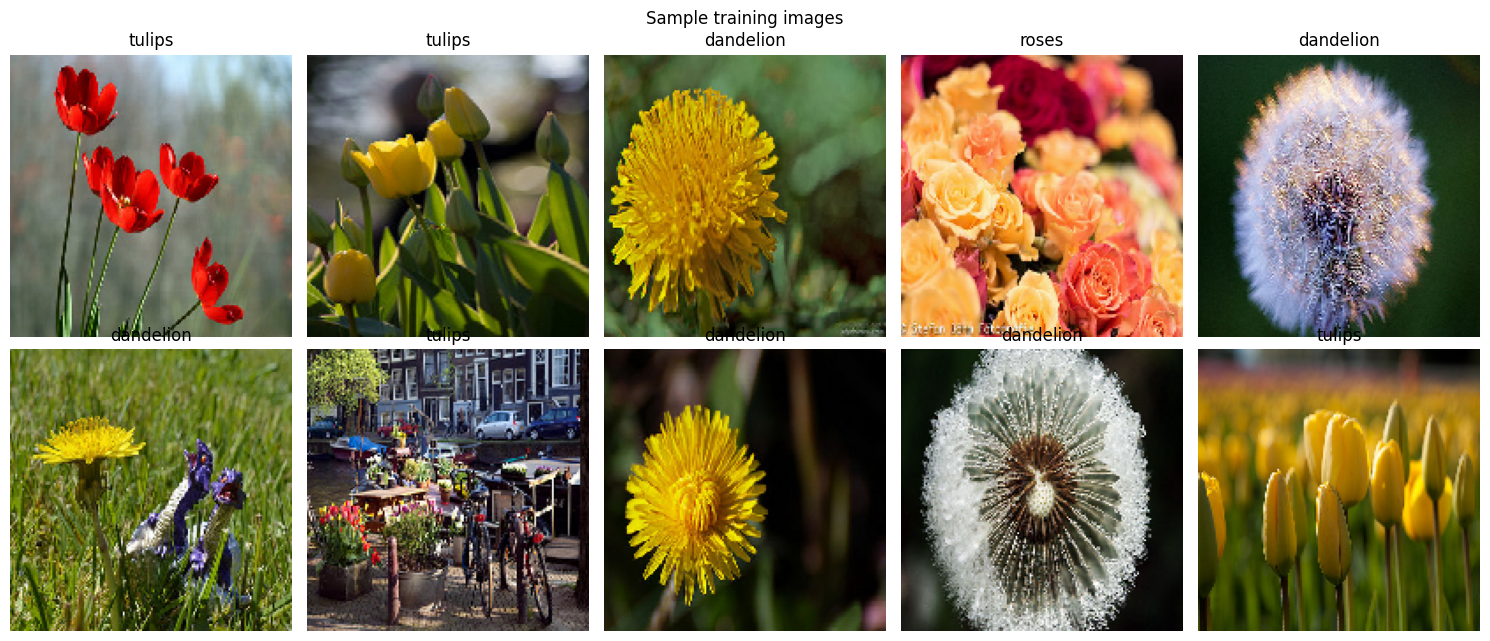

In [8]:
URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
CACHE_TGZ = P('data_cache', 'flower_photos.tgz')     # cached on Drive -> no re-download next session
DATA_DIR = '/content/flower_photos'

if not os.path.exists(CACHE_TGZ):
    p = tf.keras.utils.get_file('flower_photos.tgz', URL, cache_dir='/content/dl', cache_subdir='')
    shutil.copy(p, CACHE_TGZ)
if not os.path.isdir(DATA_DIR):
    with tarfile.open(CACHE_TGZ) as t:
        t.extractall('/content')

SPLIT_PATH = P('outputs', 'split.json')
if os.path.exists(SPLIT_PATH):
    S = json.load(open(SPLIT_PATH))
    print('Loaded saved split from Drive')
else:
    classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
    items = [(f'{c}/{f}', i) for i, c in enumerate(classes)
             for f in sorted(os.listdir(os.path.join(DATA_DIR, c))) if f.lower().endswith('.jpg')]
    paths = [p for p, _ in items]; ys = [y for _, y in items]
    p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, ys, test_size=0.30, stratify=ys, random_state=SEED)
    p_va, p_te, y_va, y_te = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
    S = dict(classes=classes, train=[p_tr, y_tr], val=[p_va, y_va], test=[p_te, y_te])
    json.dump(S, open(SPLIT_PATH, 'w'))
    print('Created and saved new split')

classes = S['classes']; NUM_CLASSES = len(classes)
def unpack(k):
    return [os.path.join(DATA_DIR, p) for p in S[k][0]], np.array(S[k][1], dtype='int32')
(tr_x, tr_y), (va_x, va_y), (te_x, te_y) = unpack('train'), unpack('val'), unpack('test')

print('Classes:', classes)
print(f'train={len(tr_x)}  val={len(va_x)}  test={len(te_x)}')
print(pd.DataFrame({'train': np.bincount(tr_y), 'val': np.bincount(va_y), 'test': np.bincount(te_y)}, index=classes))

# sample grid
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
rng = np.random.default_rng(0)
for ax, i in zip(axes.ravel(), rng.choice(len(tr_x), 10, replace=False)):
    ax.imshow(keras.utils.load_img(tr_x[i], target_size=(160, 160))); ax.set_title(classes[tr_y[i]]); ax.axis('off')
plt.suptitle('Sample training images'); plt.tight_layout(); save_fig('01_sample_images.png'); plt.show()

In [4]:
IMG, BATCH = 160, 32
AUTOTUNE = tf.data.AUTOTUNE

def _load(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(tf.round(img), tf.uint8), label        # uint8 keeps the RAM cache small

def make_ds(x, y, train):
    ds = tf.data.Dataset.from_tensor_slices((x, y)).map(_load, num_parallel_calls=AUTOTUNE).cache()
    if train:
        ds = ds.shuffle(len(x), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH).map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(tr_x, tr_y, True), make_ds(va_x, va_y, False), make_ds(te_x, te_y, False)
print('Datasets ready (cached in RAM after first epoch).')

Datasets ready (cached in RAM after first epoch).


In [5]:
def get_augmentation():
    return keras.Sequential([layers.RandomFlip('horizontal'),
                             layers.RandomRotation(0.08),
                             layers.RandomZoom(0.10)], name='augmentation')

def get_callbacks(name, patience):
    return [
        keras.callbacks.ModelCheckpoint(P('models', f'{name}_best.keras'), monitor='val_accuracy',
                                        save_best_only=True, verbose=0),
        keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
        keras.callbacks.BackupAndRestore(P('backup', name)),
    ]

def train_or_load(name, model, epochs, lr, patience=6):
    best, hpath = P('models', f'{name}_best.keras'), P('history', f'{name}.json')
    if os.path.exists(best) and os.path.exists(hpath) and not FORCE_RETRAIN:
        print(f'[{name}] found on Drive -> loading instead of retraining')
        return keras.models.load_model(best), json.load(open(hpath))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=get_callbacks(name, patience), verbose=2)
    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    hist['train_time_s'] = time.time() - t0
    json.dump(hist, open(hpath, 'w'))
    model.save(P('models', f'{name}_final.keras'))
    print(f'[{name}] trained in {hist["train_time_s"]/60:.1f} min; saved to Drive')
    return keras.models.load_model(best), hist

def evaluate_model(name, model, hist, pretty):
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    y_true = np.concatenate([y for _, y in test_ds])
    probs = model.predict(test_ds, verbose=0); y_pred = probs.argmax(1)
    # latency: 32-image batch, averaged over 10 runs (includes Keras predict overhead)
    xb = next(iter(test_ds.take(1)))[0]; model.predict(xb, verbose=0)
    t0 = time.time()
    for _ in range(10): model.predict(xb, verbose=0)
    ms_per_img = (time.time() - t0) / 10 / len(xb) * 1000
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    res = dict(model=pretty, val_acc=float(val_acc), test_acc=float(test_acc), test_loss=float(test_loss),
               params_total=int(model.count_params()), params_trainable_at_end=trainable,
               file_mb=round(os.path.getsize(P('models', f'{name}_best.keras')) / 1e6, 2),
               train_time_s=float(hist.get('train_time_s', float('nan'))),
               epochs_run=len(hist['loss']), ms_per_image=float(ms_per_img))
    save_result(name, res)

    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.imshow(cm, cmap='Blues'); ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(classes, rotation=45, ha='right'); ax.set_yticklabels(classes)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{pretty}\ntest acc = {test_acc:.3f}')
    plt.tight_layout(); save_fig(f'cm_{name}.png'); plt.show()
    print(classification_report(y_true, y_pred, target_names=classes, digits=3))
    return res

def plot_history(hists, title, fname, boundary=None):
    keys = ['loss', 'accuracy', 'val_loss', 'val_accuracy']
    h = {k: sum([x[k] for x in hists], []) for k in keys}
    ep = range(1, len(h['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, h['loss'], label='train'); ax[0].plot(ep, h['val_loss'], label='val'); ax[0].set_title('Loss')
    ax[1].plot(ep, h['accuracy'], label='train'); ax[1].plot(ep, h['val_accuracy'], label='val'); ax[1].set_title('Accuracy')
    for a in ax:
        a.set_xlabel('epoch'); a.legend(); a.grid(alpha=.3)
        if boundary: a.axvline(boundary + .5, color='gray', ls='--')
    plt.suptitle(title); plt.tight_layout(); save_fig(fname); plt.show()

In [6]:
def build_small_cnn():
    inp = keras.Input((IMG, IMG, 3), name='image')
    x = layers.Rescaling(1. / 255, name='rescale')(inp)
    x = get_augmentation()(x)

    x = layers.Conv2D(32, 5, strides=2, padding='same', use_bias=False, name='conv1')(x)   # 160 -> 80
    x = layers.BatchNormalization(name='bn1')(x); x = layers.ReLU(name='relu1')(x)
    x = layers.MaxPooling2D(2, name='pool1')(x)                                             # 80 -> 40

    x = layers.Conv2D(64, 3, padding='same', use_bias=False, name='conv2')(x)               # 40 -> 40
    x = layers.BatchNormalization(name='bn2')(x); x = layers.ReLU(name='relu2')(x)
    x = layers.MaxPooling2D(2, name='pool2')(x)                                             # 40 -> 20

    x = layers.Conv2D(128, 3, padding='valid', use_bias=False, name='conv3')(x)             # 20 -> 18
    x = layers.BatchNormalization(name='bn3')(x); x = layers.ReLU(name='relu3')(x)
    x = layers.MaxPooling2D(2, name='pool3')(x)                                             # 18 -> 9

    x = layers.Conv2D(128, 3, padding='same', use_bias=False, name='conv4')(x)              # 9 -> 9
    x = layers.BatchNormalization(name='bn4')(x); x = layers.ReLU(name='relu4')(x)
    x = layers.MaxPooling2D(2, name='pool4')(x)                                             # 9 -> 4

    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.4, name='dropout')(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='classifier')(x)
    return keras.Model(inp, out, name='small_cnn')

small_cnn = build_small_cnn()
small_cnn.summary()

# check the output-size formula against what Keras reports
def out_size(W, K, S, padding):
    return -(-W // S) if padding == 'same' else (W - K) // S + 1
print('\nconv1:', out_size(160, 5, 2, 'same'), '| conv3 (valid):', out_size(20, 3, 1, 'valid'),
      '| pool4 on 9x9 ->', 9 // 2)

Model: "small_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescale (Rescaling)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 80, 80, 32)     │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 80, 80, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (ReLU)                    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 40, 40, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 40, 40, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (ReLU)                    │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 18, 18, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 18, 18, 128)    │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (ReLU)                    │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 9, 9, 128)      │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 9, 9, 128)      │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (ReLU)                    │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool4 (MaxPooling2D)            │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,069 (953.39 KB)

 Trainable params: 243,365 (950.64 KB)

 Non-trainable params: 704 (2.75 KB)


conv1: 80 | conv3 (valid): 18 | pool4 on 9x9 -> 4


Epoch 1/25
81/81 - 16s - 202ms/step - accuracy: 0.5037 - loss: 1.3125 - val_accuracy: 0.2436 - val_loss: 1.7608 - learning_rate: 0.0010
Epoch 2/25
81/81 - 2s - 28ms/step - accuracy: 0.5718 - loss: 1.1045 - val_accuracy: 0.2436 - val_loss: 2.1010 - learning_rate: 0.0010
Epoch 3/25
81/81 - 2s - 29ms/step - accuracy: 0.6162 - loss: 0.9706 - val_accuracy: 0.2491 - val_loss: 1.9551 - learning_rate: 0.0010
Epoch 4/25
81/81 - 2s - 28ms/step - accuracy: 0.6275 - loss: 0.9184 - val_accuracy: 0.4818 - val_loss: 1.2670 - learning_rate: 0.0010
Epoch 5/25
81/81 - 2s - 27ms/step - accuracy: 0.6520 - loss: 0.9033 - val_accuracy: 0.4236 - val_loss: 1.5568 - learning_rate: 0.0010
Epoch 6/25
81/81 - 3s - 33ms/step - accuracy: 0.6847 - loss: 0.8281 - val_accuracy: 0.6527 - val_loss: 0.9537 - learning_rate: 0.0010
Epoch 7/25
81/81 - 2s - 27ms/step - accuracy: 0.6902 - loss: 0.7980 - val_accuracy: 0.5545 - val_loss: 1.1992 - learning_rate: 0.0010
Epoch 8/25
81/81 - 2s - 27ms/step - accuracy: 0.7073 - loss:

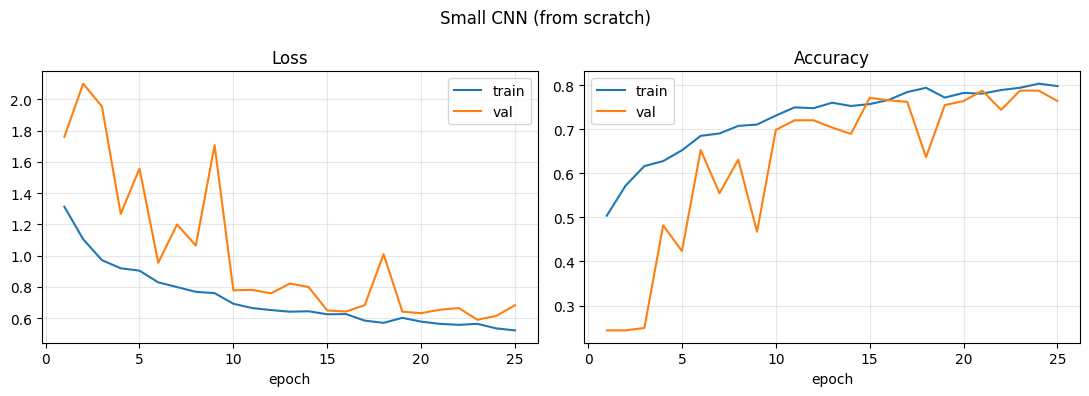

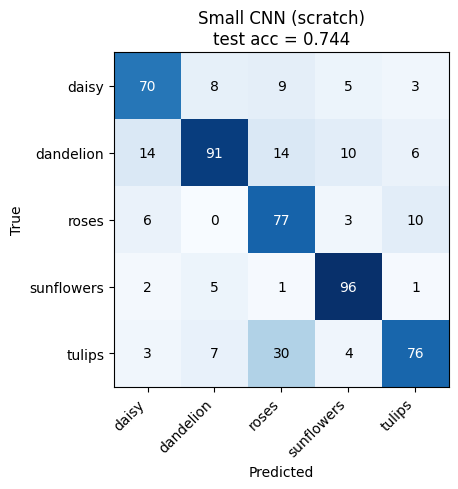

              precision    recall  f1-score   support

       daisy      0.737     0.737     0.737        95
   dandelion      0.820     0.674     0.740       135
       roses      0.588     0.802     0.678        96
  sunflowers      0.814     0.914     0.861       105
      tulips      0.792     0.633     0.704       120

    accuracy                          0.744       551
   macro avg      0.750     0.752     0.744       551
weighted avg      0.758     0.744     0.744       551



{'model': 'Small CNN (scratch)',
 'val_acc': 0.7872727513313293,
 'test_acc': 0.7441016435623169,
 'test_loss': 0.7352173924446106,
 'params_total': 244069,
 'params_trainable_at_end': 243365,
 'file_mb': 3.02,
 'train_time_s': 71.81737875938416,
 'epochs_run': 25,
 'ms_per_image': 2.375146746635437}

In [7]:
small_model, hist_small = train_or_load('small_cnn', small_cnn, epochs=25, lr=1e-3, patience=7)
plot_history([hist_small], 'Small CNN (from scratch)', '02_curves_small_cnn.png')
res_small = evaluate_model('small_cnn', small_model, hist_small, 'Small CNN (scratch)')
res_small

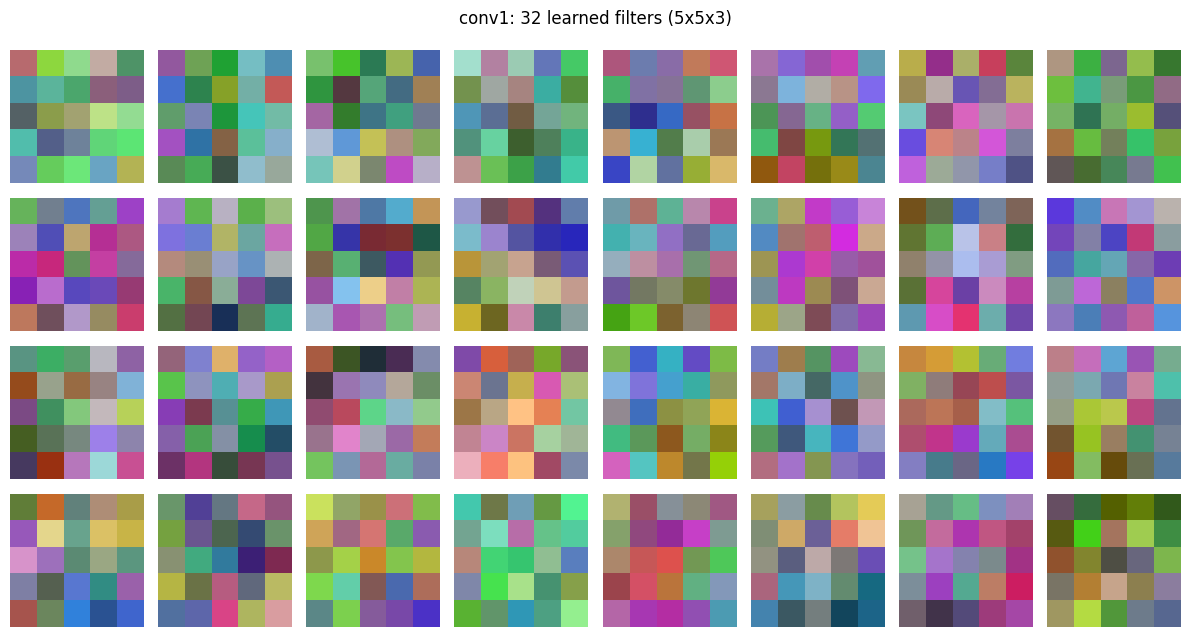

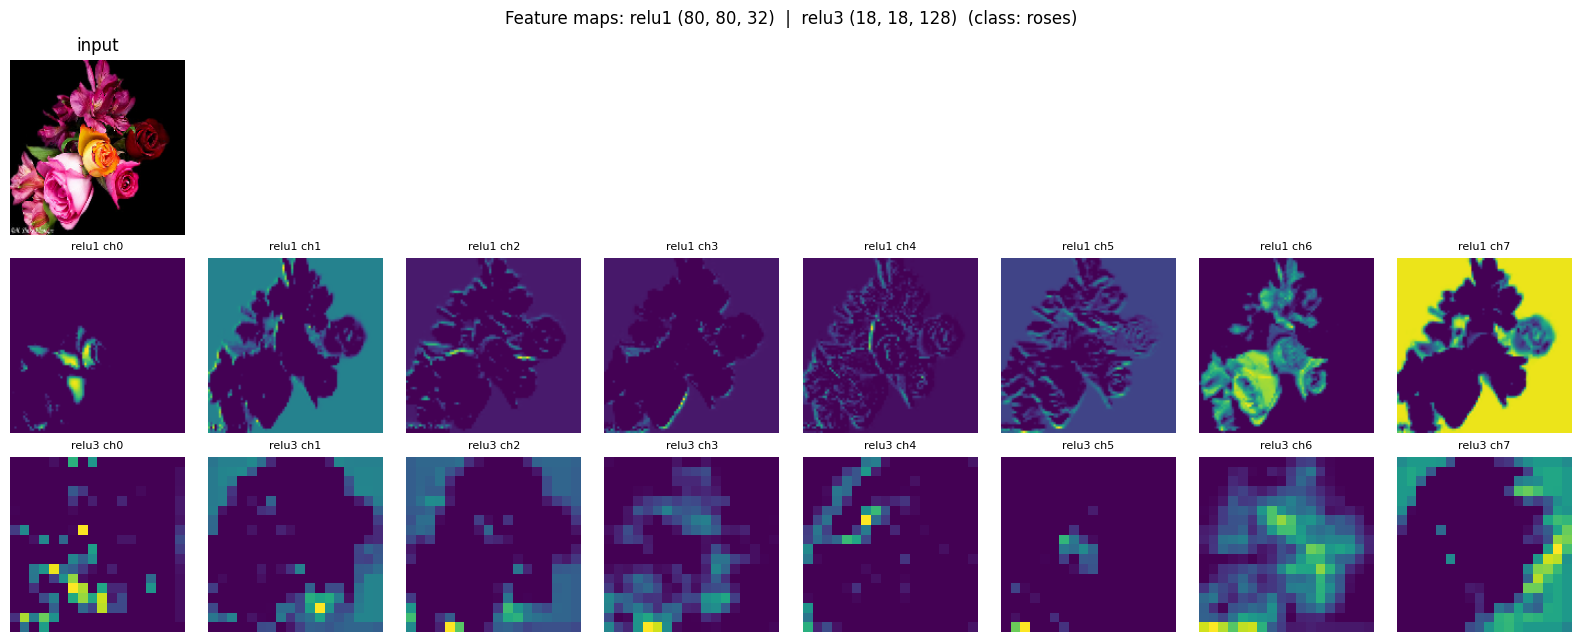

In [8]:
# --- learned 5x5 filters of the first conv layer ---
w = small_model.get_layer('conv1').get_weights()[0]                     # (5, 5, 3, 32)
w = (w - w.min()) / (w.max() - w.min())
fig, axes = plt.subplots(4, 8, figsize=(12, 6.5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(w[:, :, :, i]); ax.axis('off')
plt.suptitle('conv1: 32 learned filters (5x5x3)'); plt.tight_layout(); save_fig('03_conv1_filters.png'); plt.show()

# --- feature maps for one test image ---
img = keras.utils.load_img(te_x[0], target_size=(IMG, IMG))
xin = np.expand_dims(np.array(img, dtype='float32'), 0)
fm_model = keras.Model(small_model.input, [small_model.get_layer(n).output for n in ['relu1', 'relu3']])
fm1, fm3 = fm_model.predict(xin, verbose=0)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for j in range(8):
    if j == 0: axes[0, 0].imshow(img); axes[0, 0].set_title('input')
    axes[1, j].imshow(fm1[0, :, :, j], cmap='viridis'); axes[2, j].imshow(fm3[0, :, :, j], cmap='viridis')
    axes[1, j].set_title(f'relu1 ch{j}', fontsize=8); axes[2, j].set_title(f'relu3 ch{j}', fontsize=8)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle(f'Feature maps: relu1 {fm1.shape[1:]}  |  relu3 {fm3.shape[1:]}  (class: {classes[te_y[0]]})')
plt.tight_layout(); save_fig('04_feature_maps.png'); plt.show()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total params: 2,264,389 | trainable: 6,405
Epoch 1/10
81/81 - 13s - 160ms/step - accuracy: 0.6236 - loss: 0.9893 - val_accuracy: 0.8091 - val_loss: 0.5710 - learning_rate: 0.0010
Epoch 2/10
81/81 - 6s - 74ms/step - accuracy: 0.8241 - loss: 0.4897 - val_accuracy: 0.8400 - val_loss: 0.4680 - learning_rate: 0.0010
Epoch 3/10
81/81 - 4s - 52ms/step - accuracy: 0.8466 - loss: 0.4141 - val_accuracy: 0.8618 - val_loss: 0.4168 - learning_rate: 0.0010
Epoch 4/10
81/81 - 4s - 44ms/step - accuracy: 0.8684 - loss: 0.3587 - val_accuracy: 0.8491 - val_loss: 0.4036 - learning_rate: 0.0010
Epoch 5/10
81/81 - 5s - 65ms/step - accuracy: 0.8879 - loss: 0.3149 - val_accuracy: 0.8527 - val_loss: 0.4032 - learning_rate: 0.0010
Epoch 6/10
81/81 - 4s - 46ms/step - accuracy: 0.8910 - loss: 0.3060 - val_accuracy: 0.8600 - val_loss: 0.3899 - learning_rate: 0.0010
Epoch 7/10
81/81 - 4s - 52ms/step - accuracy: 0.8976 - loss: 0.2837 - val_accuracy: 0.8782 - val_loss:

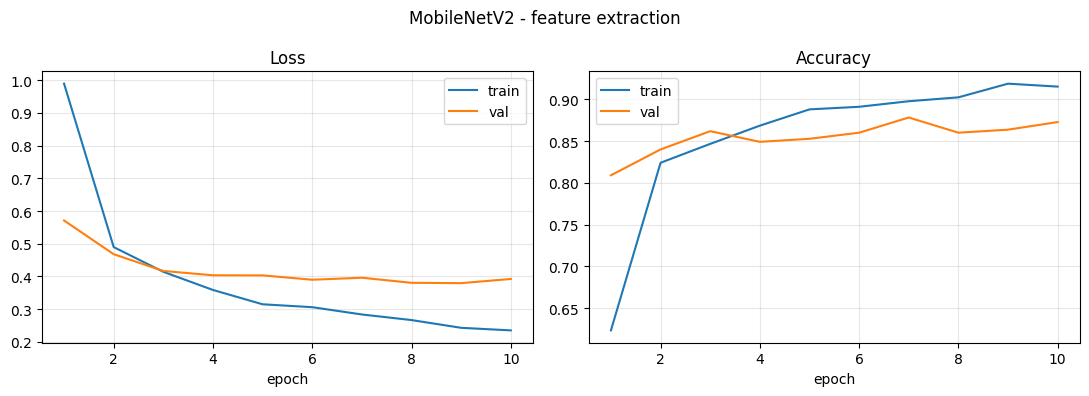

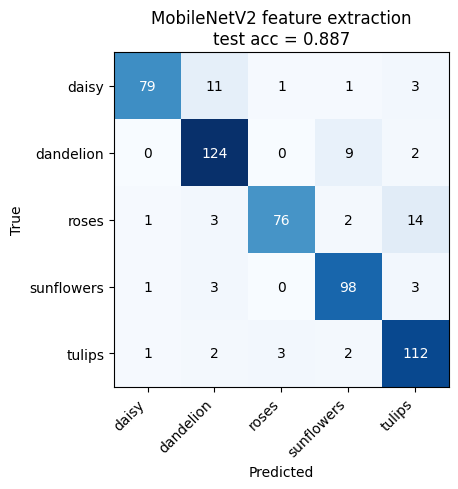

              precision    recall  f1-score   support

       daisy      0.963     0.832     0.893        95
   dandelion      0.867     0.919     0.892       135
       roses      0.950     0.792     0.864        96
  sunflowers      0.875     0.933     0.903       105
      tulips      0.836     0.933     0.882       120

    accuracy                          0.887       551
   macro avg      0.898     0.882     0.887       551
weighted avg      0.893     0.887     0.887       551



{'model': 'MobileNetV2 feature extraction',
 'val_acc': 0.8781818151473999,
 'test_acc': 0.8874773383140564,
 'test_loss': 0.32550302147865295,
 'params_total': 2264389,
 'params_trainable_at_end': 6405,
 'file_mb': 9.71,
 'train_time_s': 51.54456901550293,
 'epochs_run': 10,
 'ms_per_image': 3.495790809392929}

In [9]:
def build_mobilenet_fe():
    base = keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights='imagenet')
    base.trainable = False
    inp = keras.Input((IMG, IMG, 3), name='image')
    x = layers.Rescaling(1. / 127.5, offset=-1, name='mobilenet_preprocess')(inp)   # -> [-1, 1] as MobileNetV2 expects
    x = get_augmentation()(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(0.2, name='dropout')(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax', name='classifier')(x)
    return keras.Model(inp, out, name='mobilenetv2_fe')

fe_model_new = build_mobilenet_fe()
print('Total params:', f'{fe_model_new.count_params():,}',
      '| trainable:', f'{int(sum(np.prod(w.shape) for w in fe_model_new.trainable_weights)):,}')

fe_model, hist_fe = train_or_load('mobilenetv2_fe', fe_model_new, epochs=10, lr=1e-3, patience=4)
plot_history([hist_fe], 'MobileNetV2 - feature extraction', '05_curves_feature_extraction.png')
res_fe = evaluate_model('mobilenetv2_fe', fe_model, hist_fe, 'MobileNetV2 feature extraction')
res_fe

Trainable params now: 6,405 of 2,264,389
Epoch 1/10
81/81 - 10s - 124ms/step - accuracy: 0.9116 - loss: 0.2530 - val_accuracy: 0.8764 - val_loss: 0.3773 - learning_rate: 3.0000e-05
Epoch 2/10
81/81 - 4s - 53ms/step - accuracy: 0.9140 - loss: 0.2458 - val_accuracy: 0.8818 - val_loss: 0.3752 - learning_rate: 3.0000e-05
Epoch 3/10
81/81 - 4s - 46ms/step - accuracy: 0.9058 - loss: 0.2535 - val_accuracy: 0.8818 - val_loss: 0.3740 - learning_rate: 3.0000e-05
Epoch 4/10
81/81 - 5s - 56ms/step - accuracy: 0.9093 - loss: 0.2519 - val_accuracy: 0.8818 - val_loss: 0.3743 - learning_rate: 3.0000e-05
Epoch 5/10
81/81 - 5s - 56ms/step - accuracy: 0.9186 - loss: 0.2406 - val_accuracy: 0.8818 - val_loss: 0.3738 - learning_rate: 3.0000e-05
Epoch 6/10
81/81 - 4s - 46ms/step - accuracy: 0.9101 - loss: 0.2431 - val_accuracy: 0.8800 - val_loss: 0.3743 - learning_rate: 3.0000e-05
Epoch 7/10
81/81 - 4s - 46ms/step - accuracy: 0.9124 - loss: 0.2506 - val_accuracy: 0.8818 - val_loss: 0.3739 - learning_rate: 3.

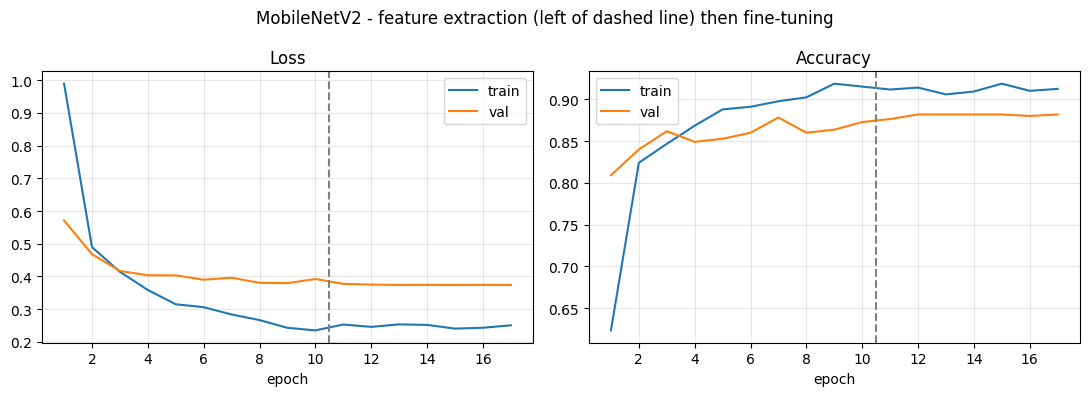

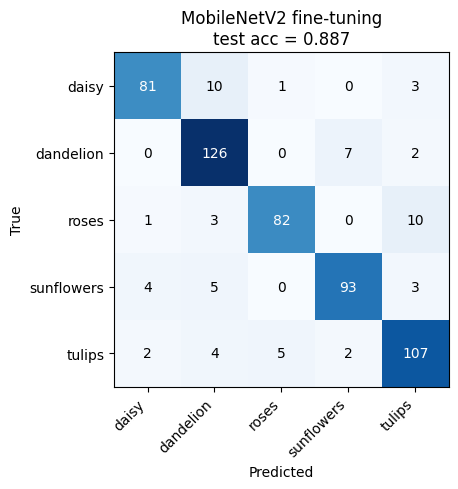

              precision    recall  f1-score   support

       daisy      0.920     0.853     0.885        95
   dandelion      0.851     0.933     0.890       135
       roses      0.932     0.854     0.891        96
  sunflowers      0.912     0.886     0.899       105
      tulips      0.856     0.892     0.873       120

    accuracy                          0.887       551
   macro avg      0.894     0.884     0.888       551
weighted avg      0.890     0.887     0.888       551



{'model': 'MobileNetV2 fine-tuning',
 'val_acc': 0.8818181753158569,
 'test_acc': 0.8874773383140564,
 'test_loss': 0.30919480323791504,
 'params_total': 2264389,
 'params_trainable_at_end': 6405,
 'file_mb': 9.7,
 'train_time_s': 34.76564025878906,
 'epochs_run': 7,
 'ms_per_image': 3.4354977309703827}

In [10]:
# ---- fine-tuning: start from the best feature-extraction weights, unfreeze the top 30 backbone layers ----
FE_BEST = P('models', 'mobilenetv2_fe_best.keras')
ft_start = keras.models.load_model(FE_BEST)
base = [l for l in ft_start.layers if isinstance(l, keras.Model)][0]
base.trainable = True
UNFREEZE_LAST = 30
for l in base.layers[:-UNFREEZE_LAST]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False                       # keep BN statistics stable with a small dataset
print('Trainable params now:', f'{int(sum(np.prod(w.shape) for w in ft_start.trainable_weights)):,}',
      'of', f'{ft_start.count_params():,}')

ft_model, hist_ft = train_or_load('mobilenetv2_ft', ft_start, epochs=10, lr=3e-5, patience=5)
plot_history([hist_fe, hist_ft], 'MobileNetV2 - feature extraction (left of dashed line) then fine-tuning',
             '06_curves_finetuning.png', boundary=len(hist_fe['loss']))
res_ft = evaluate_model('mobilenetv2_ft', ft_model, hist_ft, 'MobileNetV2 fine-tuning')
res_ft

,val_acc,test_acc,params_total,params_trainable_at_end,file_mb,epochs_run,ms_per_image,train_time_min
model,,,,,,,,
Small CNN (scratch),0.7873,0.7441,244069,243365,3.02,25,2.3751,1.20
MobileNetV2 feature extraction,0.8782,0.8875,2264389,6405,9.71,10,3.4958,0.86
MobileNetV2 fine-tuning,0.8818,0.8875,2264389,6405,9.70,7,3.4355,0.58


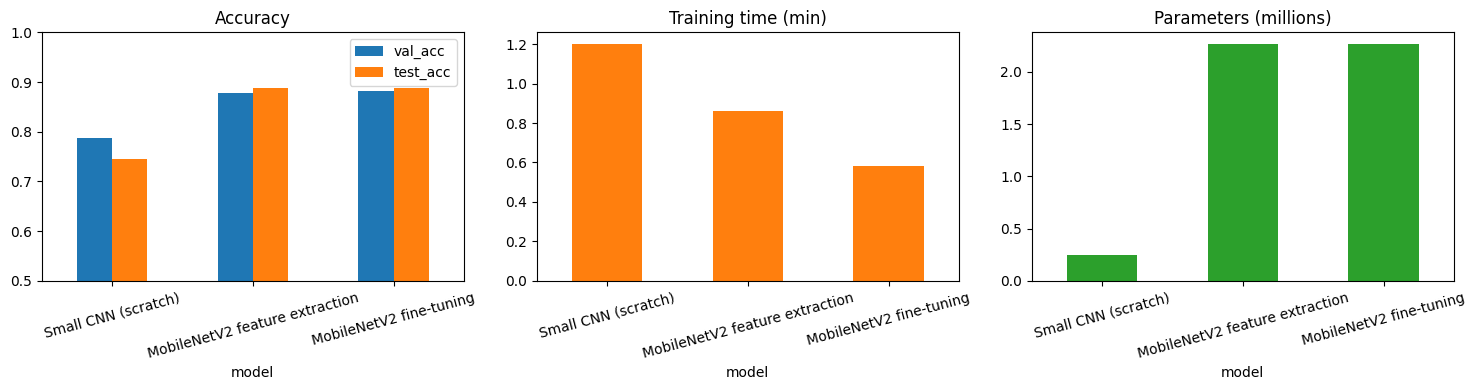

Best model by validation accuracy: mobilenetv2_ft


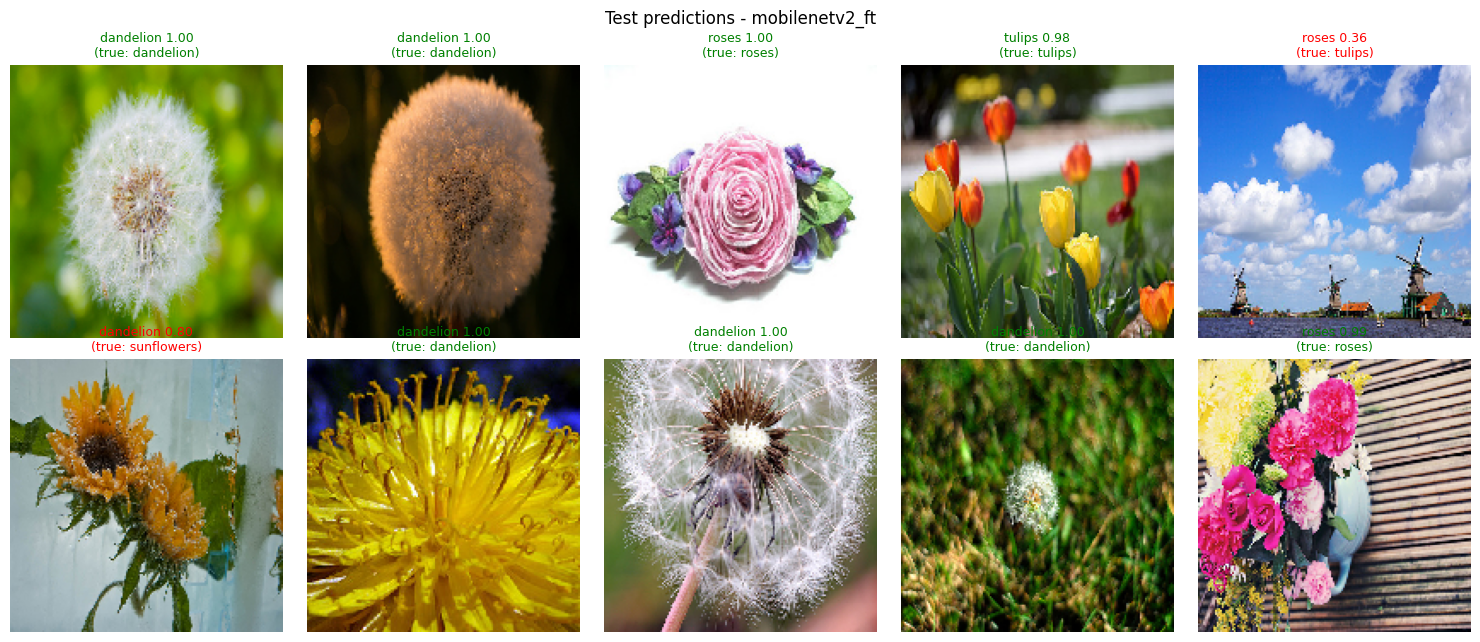

In [11]:
R = load_results()
rows = [R[k] for k in ['small_cnn', 'mobilenetv2_fe', 'mobilenetv2_ft'] if k in R]
cmp_df = pd.DataFrame(rows).set_index('model')
cmp_df['train_time_min'] = (cmp_df['train_time_s'] / 60).round(2)
cmp_df = cmp_df.drop(columns=['train_time_s', 'test_loss'])
cmp_df.to_csv(P('outputs', 'classification_comparison.csv'))
display(cmp_df.round(4))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cmp_df[['val_acc', 'test_acc']].plot.bar(ax=ax[0], rot=15); ax[0].set_ylim(0.5, 1); ax[0].set_title('Accuracy')
cmp_df['train_time_min'].plot.bar(ax=ax[1], rot=15, color='tab:orange'); ax[1].set_title('Training time (min)')
(cmp_df['params_total'] / 1e6).plot.bar(ax=ax[2], rot=15, color='tab:green'); ax[2].set_title('Parameters (millions)')
plt.tight_layout(); save_fig('07_classifier_comparison.png'); plt.show()

# a few test predictions from the best model
best_key = max(['small_cnn', 'mobilenetv2_fe', 'mobilenetv2_ft'], key=lambda k: R[k]['val_acc'])   # chosen on VAL
best_model = {'small_cnn': small_model, 'mobilenetv2_fe': fe_model, 'mobilenetv2_ft': ft_model}[best_key]
print('Best model by validation accuracy:', best_key)
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for ax, i in zip(axes.ravel(), np.random.default_rng(1).choice(len(te_x), 10, replace=False)):
    im = keras.utils.load_img(te_x[i], target_size=(IMG, IMG))
    p = best_model.predict(np.expand_dims(np.array(im, dtype='float32'), 0), verbose=0)[0]
    ax.imshow(im); ax.axis('off')
    ax.set_title(f'{classes[p.argmax()]} {p.max():.2f}\n(true: {classes[te_y[i]]})', fontsize=9,
                 color='green' if p.argmax() == te_y[i] else 'red')
plt.suptitle(f'Test predictions - {best_key}'); plt.tight_layout(); save_fig('08_test_predictions.png'); plt.show()

In [3]:
import torch, torchvision, requests
from PIL import Image
import torchvision.transforms.functional as TF
from torchvision.models import detection as det

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| device:', dev)

DET_DIR = P('outputs', 'det_images'); os.makedirs(DET_DIR, exist_ok=True)
COCO_IDS = ['000000039769', '000000000139', '000000000285', '000000000724', '000000000785', '000000001000']
for cid in COCO_IDS:
    fp = os.path.join(DET_DIR, f'{cid}.jpg')
    if not os.path.exists(fp):
        try:
            r = requests.get(f'http://images.cocodataset.org/val2017/{cid}.jpg', timeout=20); r.raise_for_status()
            open(fp, 'wb').write(r.content)
        except Exception as e:
            print('could not download', cid, e)
det_files = sorted(os.path.join(DET_DIR, f) for f in os.listdir(DET_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
print(len(det_files), 'images for detection')

DET_MODELS = {
    'FasterRCNN-ResNet50-FPN':    (det.fasterrcnn_resnet50_fpn,            det.FasterRCNN_ResNet50_FPN_Weights.DEFAULT),
    'FasterRCNN-MobileNetV3-FPN': (det.fasterrcnn_mobilenet_v3_large_fpn,  det.FasterRCNN_MobileNet_V3_Large_FPN_Weights.DEFAULT),
    'SSDlite320-MobileNetV3':     (det.ssdlite320_mobilenet_v3_large,      det.SSDLite320_MobileNet_V3_Large_Weights.DEFAULT),
}
CATS = det.FasterRCNN_ResNet50_FPN_Weights.DEFAULT.meta['categories']
THR = 0.5

@torch.no_grad()
def detect(model, pil_img):
    x = TF.to_tensor(pil_img).to(dev)
    if dev == 'cuda': torch.cuda.synchronize()
    t0 = time.time()
    out = model([x])[0]
    if dev == 'cuda': torch.cuda.synchronize()
    dt = time.time() - t0
    keep = out['scores'] >= THR
    return (out['boxes'][keep].cpu().numpy(), out['labels'][keep].cpu().numpy(),
            out['scores'][keep].cpu().numpy(), dt)

imgs = [Image.open(f).convert('RGB') for f in det_files]
all_dets, det_rows, timing = {}, [], []
for name, (fn, weights) in DET_MODELS.items():
    model = fn(weights=weights).to(dev).eval()
    n_params = sum(p.numel() for p in model.parameters())
    if dev == 'cuda': torch.cuda.reset_peak_memory_stats()
    detect(model, imgs[0])                                  # warm-up (not timed)
    all_dets[name], times = [], []
    for f, im in zip(det_files, imgs):
        b, l, s, dt = detect(model, im)
        all_dets[name].append((b, l, s)); times.append(dt)
        for bb, ll, ss in zip(b, l, s):
            det_rows.append(dict(model=name, image=os.path.basename(f), label=CATS[ll], score=round(float(ss), 4),
                                 x1=round(float(bb[0]), 1), y1=round(float(bb[1]), 1),
                                 x2=round(float(bb[2]), 1), y2=round(float(bb[3]), 1)))
    timing.append(dict(model=name, params_M=round(n_params / 1e6, 2),
                       avg_ms_per_image=round(1000 * float(np.mean(times)), 1),
                       fps=round(1 / float(np.mean(times)), 1),
                       peak_gpu_mem_MB=round(torch.cuda.max_memory_allocated() / 1e6, 0) if dev == 'cuda' else None,
                       total_detections=int(sum(len(d[0]) for d in all_dets[name]))))
    del model
    if dev == 'cuda': torch.cuda.empty_cache()
    print('done:', name)

pd.DataFrame(det_rows).to_csv(P('outputs', 'detections.csv'), index=False)
det_timing = pd.DataFrame(timing).set_index('model')
det_timing.to_csv(P('outputs', 'detection_timing.csv'))
save_result('detection', timing)
display(det_timing)

torch 2.11.0+cu130 | device: cuda
6 images for detection
done: FasterRCNN-ResNet50-FPN
Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_mobilenet_v3_large_fpn-fb6a3cc7.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 173MB/s]


done: FasterRCNN-MobileNetV3-FPN
Downloading: "https://download.pytorch.org/models/ssdlite320_mobilenet_v3_large_coco-a79551df.pth" to /root/.cache/torch/hub/checkpoints/ssdlite320_mobilenet_v3_large_coco-a79551df.pth


100%|██████████| 13.4M/13.4M [00:00<00:00, 149MB/s]


done: SSDlite320-MobileNetV3


,params_M,avg_ms_per_image,fps,peak_gpu_mem_MB,total_detections
model,,,,,
FasterRCNN-ResNet50-FPN,41.76,148.6,6.7,587.0,58
FasterRCNN-MobileNetV3-FPN,19.39,41.6,24.0,308.0,44
SSDlite320-MobileNetV3,3.44,33.9,29.5,52.0,16


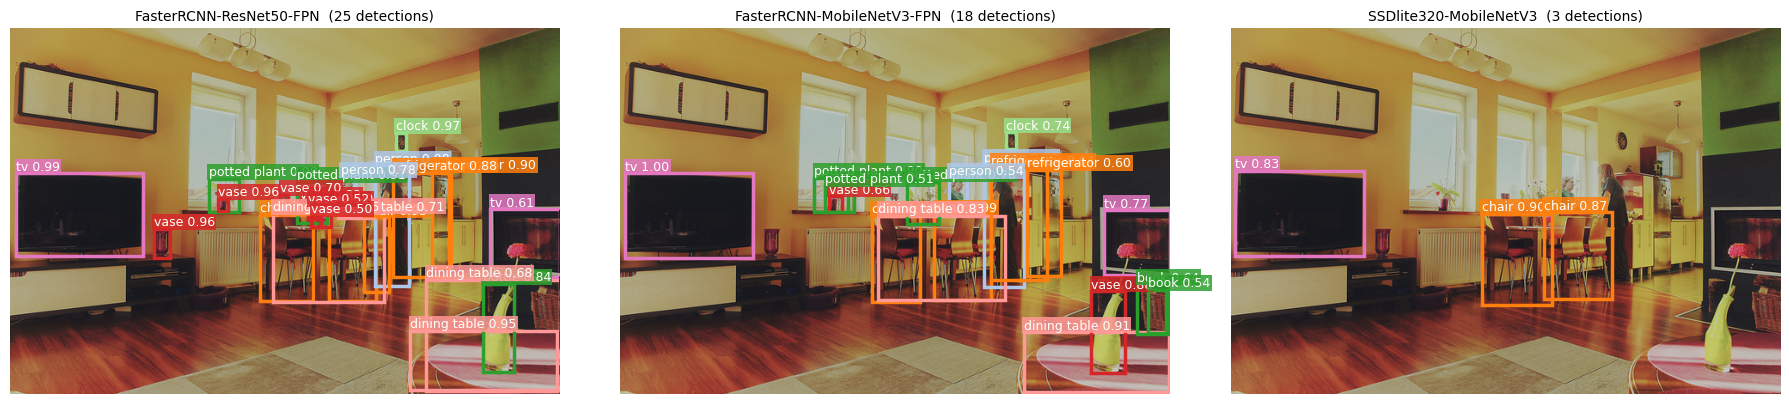

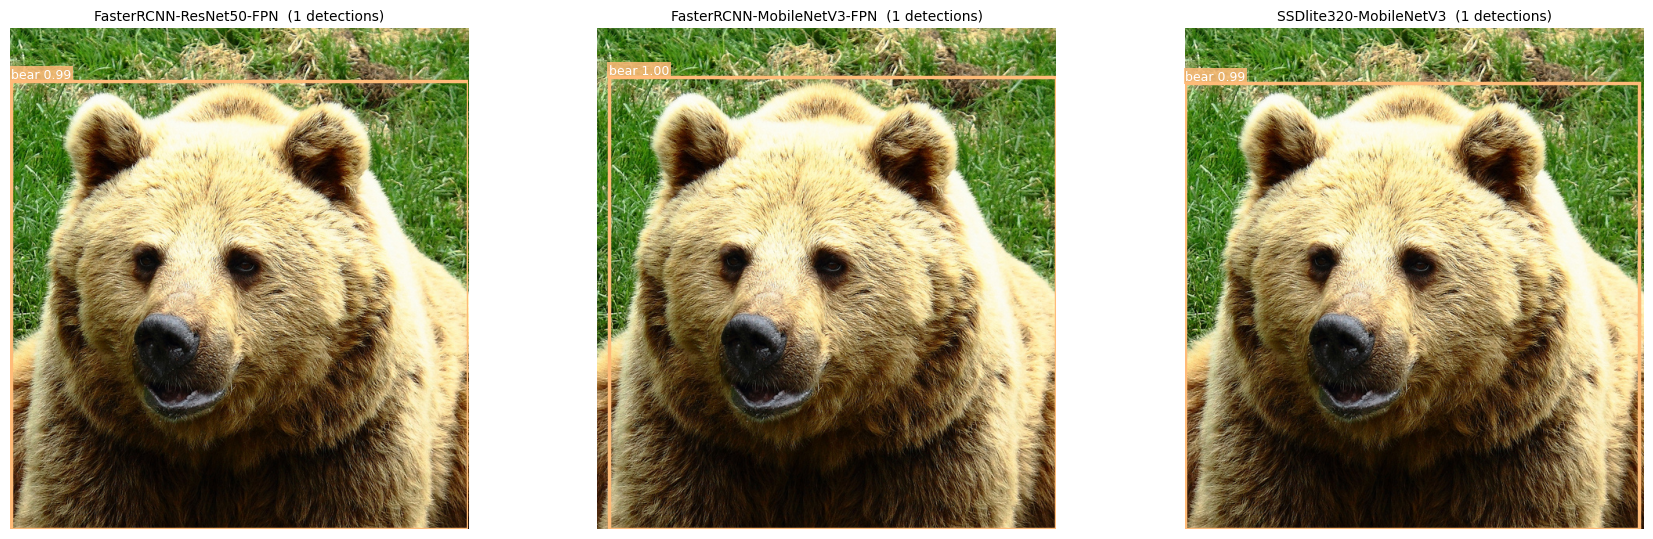

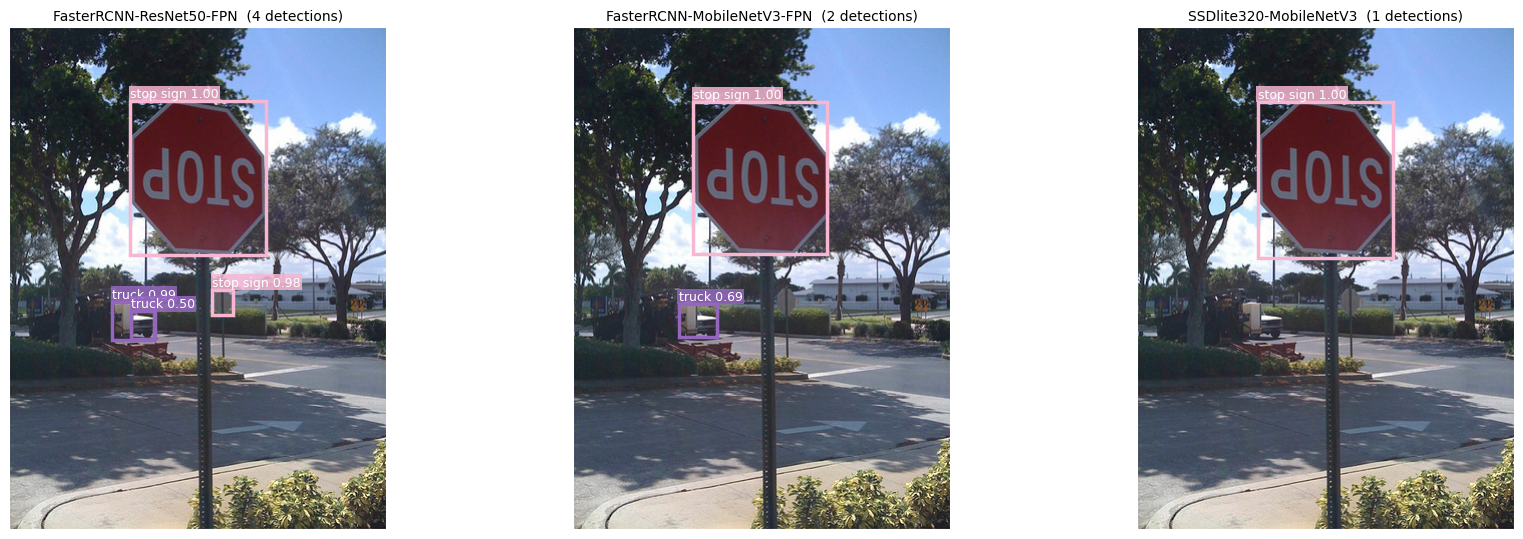

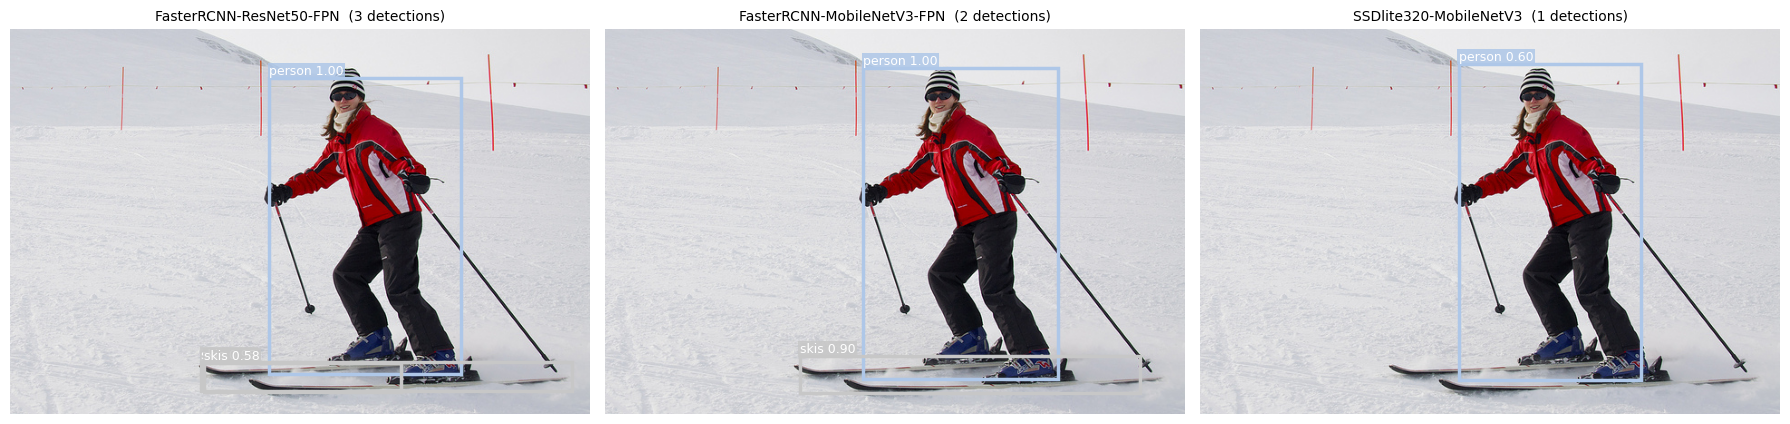

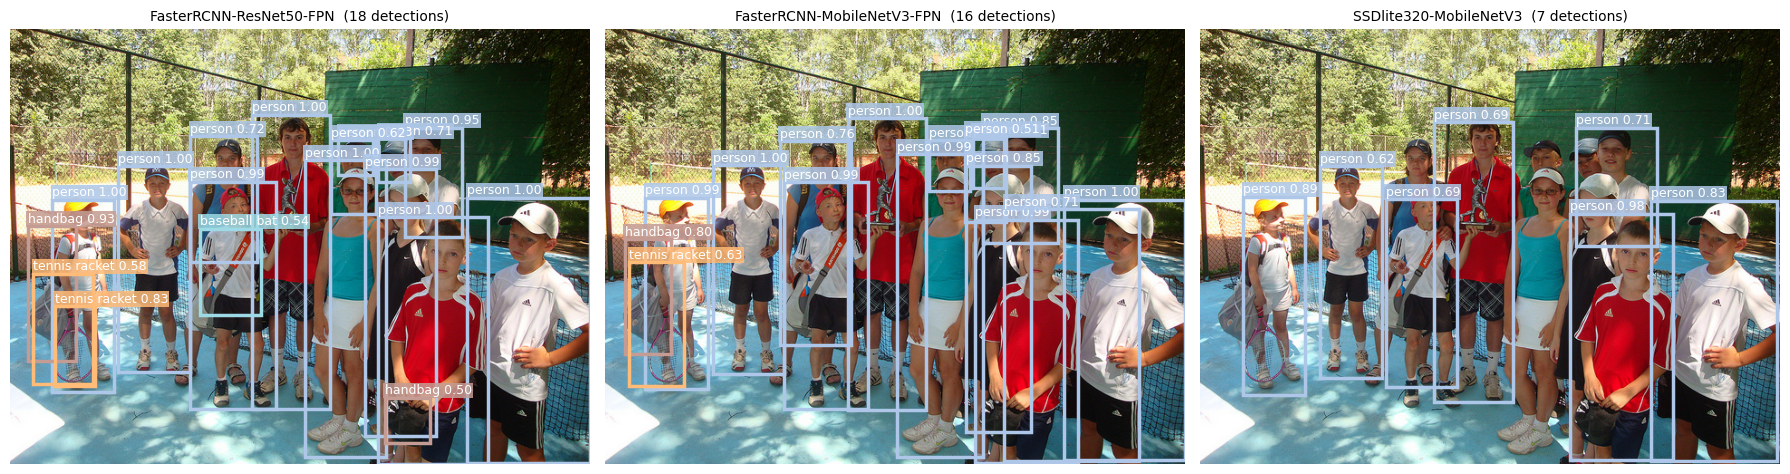

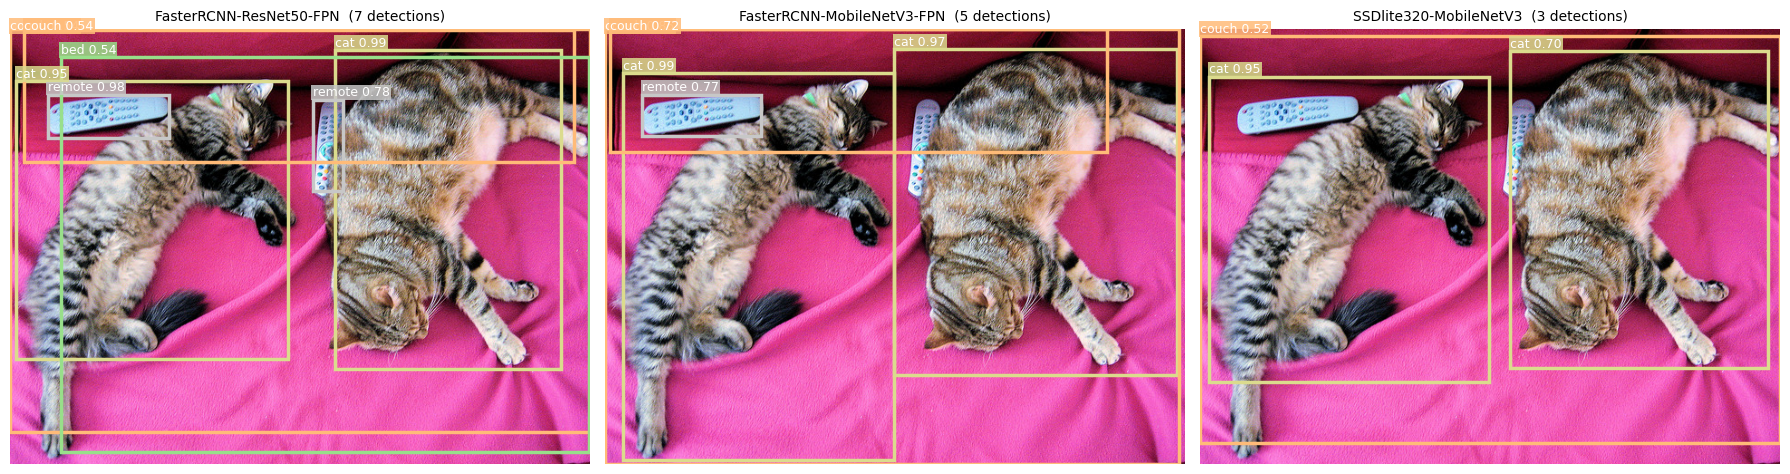

In [4]:
def draw(ax, img, boxes, labels, scores, title):
    ax.imshow(img); ax.axis('off')
    for (x1, y1, x2, y2), l, s in zip(boxes, labels, scores):
        col = plt.cm.tab20(int(l) % 20)
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=col, linewidth=2.5))
        ax.text(x1, max(y1 - 4, 0), f'{CATS[l]} {s:.2f}', fontsize=9, color='white',
                bbox=dict(facecolor=col, alpha=0.85, pad=1, edgecolor='none'))
    ax.set_title(f'{title}  ({len(boxes)} detections)', fontsize=10)

for k, (f, im) in enumerate(zip(det_files, imgs)):
    fig, axes = plt.subplots(1, len(DET_MODELS), figsize=(6 * len(DET_MODELS), 5.5))
    for ax, name in zip(axes, DET_MODELS):
        b, l, s = all_dets[name][k]
        draw(ax, im, b, l, s, name)
    plt.tight_layout(); save_fig(f'det_{k + 1:02d}_{os.path.splitext(os.path.basename(f))[0]}.png'); plt.show()

In [20]:
R = load_results(); fe, ft, sc = R['mobilenetv2_fe'], R['mobilenetv2_ft'], R['small_cnn']
better = 'fine-tuning' if ft['val_acc'] > fe['val_acc'] else 'feature extraction'
print(f"""VALIDATION PROTOCOL (identical for all three models)
- Same stratified 70/15/15 split (seed 42, saved to split.json), same augmentation, same Adam optimiser,
  same callbacks (best-val-accuracy checkpoint, early stopping, LR reduction).
- Model selection used the VALIDATION set only; the TEST set was used once for the final report.

RESULTS
- Small CNN (scratch):        val {sc['val_acc']:.3f} | test {sc['test_acc']:.3f} | {sc['params_trainable_at_end']:,} trainable params
- MobileNetV2 feature extr.:  val {fe['val_acc']:.3f} | test {fe['test_acc']:.3f} | {fe['params_trainable_at_end']:,} trainable params
- MobileNetV2 fine-tuning:    val {ft['val_acc']:.3f} | test {ft['test_acc']:.3f} | {ft['params_trainable_at_end']:,} trainable params

CONCLUSION
- Best on validation: {better}. Fine-tuning changed test accuracy by {100*(ft['test_acc']-fe['test_acc']):+.2f} points vs feature extraction.
- Transfer learning beat the scratch CNN by {100*(fe['test_acc']-sc['test_acc']):.1f} points (feature extraction) while training in similar time.
- Fine-tuning updates backbone weights, so it costs more trainable params and risks overfitting on 2.5k images;
  it only helps if the gain over feature extraction is larger than the validation noise (~1 point on 550 images).""")

VALIDATION PROTOCOL (identical for all three models)
- Same stratified 70/15/15 split (seed 42, saved to split.json), same augmentation, same Adam optimiser,
  same callbacks (best-val-accuracy checkpoint, early stopping, LR reduction).
- Model selection used the VALIDATION set only; the TEST set was used once for the final report.

RESULTS
- Small CNN (scratch):        val 0.787 | test 0.744 | 243,365 trainable params
- MobileNetV2 feature extr.:  val 0.878 | test 0.887 | 6,405 trainable params
- MobileNetV2 fine-tuning:    val 0.916 | test 0.933 | 1,517,125 trainable params

CONCLUSION
- Best on validation: fine-tuning. Fine-tuning changed test accuracy by +4.54 points vs feature extraction.
- Transfer learning beat the scratch CNN by 14.3 points (feature extraction) while training in similar time.
- Fine-tuning updates backbone weights, so it costs more trainable params and risks overfitting on 2.5k images;
  it only helps if the gain over feature extraction is larger than the valid

In [22]:
d = pd.read_csv(P('outputs', 'detections.csv'))
print(d.groupby('model').agg(detections=('score','size'), mean_conf=('score','mean')).round(3))
print('\nMost frequent classes per model:')
print(d.groupby(['model','label']).size().groupby(level=0, group_keys=False).nlargest(3))
print('\nConfidence threshold used:', THR)
print(det_timing)

                            detections  mean_conf
model                                            
FasterRCNN-MobileNetV3-FPN          44      0.826
FasterRCNN-ResNet50-FPN             58      0.832
SSDlite320-MobileNetV3              16      0.798

Most frequent classes per model:
model                       label       
FasterRCNN-MobileNetV3-FPN  person          17
                            potted plant     3
                            book             2
FasterRCNN-ResNet50-FPN     person          16
                            vase             8
                            dining table     4
SSDlite320-MobileNetV3      person           8
                            cat              2
                            chair            2
dtype: int64

Confidence threshold used: 0.5
                            params_M  avg_ms_per_image   fps  peak_gpu_mem_MB  \
model                                                                           
FasterRCNN-ResNet50-FPN        41.76         

In [23]:
R = load_results()
print('=== Classification (flower_photos, 5 classes) ===')
display(pd.read_csv(P('outputs', 'classification_comparison.csv'), index_col=0).round(4))
print('\n=== Object detection (COCO pre-trained) ===')
display(pd.read_csv(P('outputs', 'detection_timing.csv'), index_col=0))

print('\nHardware:')
!nvidia-smi --query-gpu=name,memory.total --format=csv

print('\nEverything saved on Drive:')
for root, _, files in os.walk(PROJECT):
    if '/backup' in root or '/data_cache' in root: continue
    for f in sorted(files):
        print(' ', os.path.relpath(os.path.join(root, f), PROJECT))

=== Classification (flower_photos, 5 classes) ===


,val_acc,test_acc,params_total,params_trainable_at_end,file_mb,epochs_run,ms_per_image,train_time_min
model,,,,,,,,
Small CNN (scratch),0.7873,0.7441,244069,243365,3.02,25,2.3751,1.20
MobileNetV2 feature extraction,0.8782,0.8875,2264389,6405,9.71,10,3.4958,0.86
MobileNetV2 fine-tuning,0.8818,0.8875,2264389,6405,9.70,7,3.4355,0.58



=== Object detection (COCO pre-trained) ===


,params_M,avg_ms_per_image,fps,peak_gpu_mem_MB,total_detections
model,,,,,
FasterRCNN-ResNet50-FPN,41.76,148.6,6.7,587.0,58
FasterRCNN-MobileNetV3-FPN,19.39,41.6,24.0,308.0,44
SSDlite320-MobileNetV3,3.44,33.9,29.5,52.0,16



Hardware:
name, memory.total [MiB]
Tesla T4, 15360 MiB

Everything saved on Drive:
  models/mobilenetv2_fe_best.keras
  models/mobilenetv2_fe_final.keras
  models/mobilenetv2_ft_best.keras
  models/mobilenetv2_ft_final.keras
  models/small_cnn_best.keras
  models/small_cnn_final.keras
  history/mobilenetv2_fe.json
  history/mobilenetv2_ft.json
  history/small_cnn.json
  figures/01_sample_images.png
  figures/02_curves_small_cnn.png
  figures/03_conv1_filters.png
  figures/04_feature_maps.png
  figures/05_curves_feature_extraction.png
  figures/06_curves_finetuning.png
  figures/07_classifier_comparison.png
  figures/08_test_predictions.png
  figures/cm_mobilenetv2_fe.png
  figures/cm_mobilenetv2_ft.png
  figures/cm_small_cnn.png
  figures/det_01_000000000139.png
  figures/det_02_000000000285.png
  figures/det_03_000000000724.png
  figures/det_04_000000000785.png
  figures/det_05_000000001000.png
  figures/det_06_000000039769.png
  outputs/classification_comparison.csv
  outputs/detect

In [ ]:
import glob, zipfile, shutil, json, os
from google.colab import files, _message

OUT = '/content/Assignment3_Submission'
shutil.rmtree(OUT, ignore_errors=True)
for sub in ['figures', 'results', 'models', 'detection_images']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

def grab(pattern, dest):
    found = sorted(glob.glob(pattern))
    for f in found: shutil.copy(f, f'{OUT}/{dest}/')
    return len(found)

n_fig  = grab(P('figures', '*.png'), 'figures')                  # curves, confusion matrices, filters, detections
n_res  = grab(P('outputs', '*.csv'), 'results') + grab(P('outputs', '*.json'), 'results')
n_mod  = grab(P('models', '*_best.keras'), 'models')              # best checkpoints only (skips *_final duplicates)
n_det  = grab(P('outputs', 'det_images', '*.jpg'), 'detection_images')

# short plain-text summary built from your real results
R = load_results()
lines = ['ASSIGNMENT 3 - CNN, TRANSFER LEARNING, OBJECT DETECTION', '']
for k in ['small_cnn', 'mobilenetv2_fe', 'mobilenetv2_ft']:
    if k in R:
        r = R[k]
        lines.append(f"{r['model']}: val {r['val_acc']:.3f} | test {r['test_acc']:.3f} | "
                     f"trainable params {r['params_trainable_at_end']:,} | train {r['train_time_s']/60:.1f} min")
lines += ['', 'Detection (COCO pre-trained):']
for t in R.get('detection', []):
    lines.append(f"{t['model']}: {t['avg_ms_per_image']} ms/img | {t['fps']} FPS | {t['total_detections']} detections")
open(f'{OUT}/summary.txt', 'w').write('\n'.join(lines))

# current notebook WITH its outputs (taken from the live session)
nb_name = 'Assignment3_CNN_TransferLearning_Detection.ipynb'
try:
    nb = _message.blocking_request('get_ipynb', request='', timeout_sec=600)['ipynb']
    json.dump(nb, open(f'/content/{nb_name}', 'w'))
    shutil.copy(f'/content/{nb_name}', f'{OUT}/{nb_name}')
    nb_ok = True
except Exception as e:
    print('Could not export notebook automatically:', e, '\n-> use File > Download > Download .ipynb')
    nb_ok = False

# zip everything, keep a copy on Drive
ZIP = '/content/Assignment3_Submission.zip'
with zipfile.ZipFile(ZIP, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(OUT):
        for f in fs:
            full = os.path.join(root, f); z.write(full, os.path.relpath(full, OUT))
shutil.copy(ZIP, P('outputs', 'Assignment3_Submission.zip'))

print(f'figures: {n_fig} | result files: {n_res} | models: {n_mod} | detection images: {n_det} | notebook: {nb_ok}')
print(f'zip size: {os.path.getsize(ZIP)/1e6:.1f} MB (also saved to Drive outputs/)')

files.download(ZIP)
if nb_ok: files.download(f'/content/{nb_name}')